<a href="https://colab.research.google.com/github/EverXZ/Potato_Disease_Detection/blob/main/Potato_Disease_Detection_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Detección de Enfermedad en la Hoja de la Papa.**

Ever David Osorio

Jorge Alfredo Hessen

Carlos Andrés Martinez Hoyos

**COMO CORRER EL PROYECTO**
1. Ir a https://www.kaggle.com y crear una cuenta si no tiene. Si tiene cuanta, inicie sesión.
2. Dar click en el icono del perfil ubicado arriba a la izquierda de la pantalla.
3. Una vez desplegado el menu, dar click en *Your API tokens*
4. Buscar la sección donde dice **Legacy API Credentials** y clickear donde dice **Create Legacy API Key**
5. Se descargara un archivo .JSON el cual se subirá al correr el resto de las celdas la cual le pedira que suba un archivo.

## **CARGA DE DATOS**

Cargamos los datos e instalamos las principales librerias

In [ ]:
!pip install -q kaggle

In [ ]:
!pip install pillow

In [ ]:
!pip install -q imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 5.8 MB/s eta 0:00:00


In [ ]:
from PIL import Image

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
import hashlib
import imagehash

In [ ]:
from google.colab import files
import os

if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Por favor sube tu archivo kaggle.json:")
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

# 3. Descargar y descomprimir el dataset en el almacenamiento local de la instancia Colab
!kaggle datasets download -d hafiznouman786/potato-plant-diseases-data
!unzip -q potato-plant-diseases-data.zip -d ./dataset_papa

print("¡Dataset descargado y listo en /content/dataset_papa!")

Por favor sube tu archivo kaggle.json:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/hafiznouman786/potato-plant-diseases-data
License(s): CC0-1.0
100% 75.7M/75.7M [00:00<00:00, 129MB/s]

¡Dataset descargado y listo en /content/dataset_papa!


In [ ]:
from pathlib import Path

# En Google Colab, tras el unzip, la ruta queda típicamente así:
DATASET_DIR = Path("./dataset_papa/PlantVillage/PlantVillage")

## **ANALISIS EXPLORATORIO DE DATOS**

In [ ]:
# Distribución de las clases

Total de imágenes encontradas: 2152



,Clase,Total de Muestras,Porcentaje (%)
0,Potato___Early_blight,1000,46.47
1,Potato___Late_blight,1000,46.47
2,Potato___healthy,152,7.06


/tmp/ipykernel_3194/374064486.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


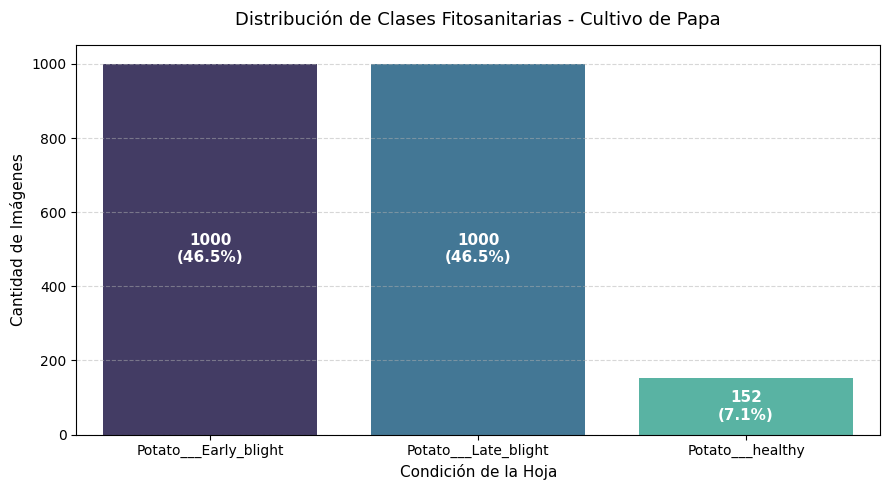

In [ ]:
registros = []
extensiones_validas = {".jpg", ".jpeg", ".png"}

for carpeta_clase in sorted(DATASET_DIR.iterdir()):
    if carpeta_clase.is_dir():
        nombre_clase = carpeta_clase.name
        # Filtrar solo archivos de imagen reales
        imagenes = [f for f in carpeta_clase.glob("*.*") if f.suffix.lower() in extensiones_validas]

        for img_path in imagenes:
            registros.append({
                "clase": nombre_clase,
                "nombre_archivo": img_path.name,
                "ruta_completa": str(img_path)
            })

# 3. Crear DataFrame con Pandas
df_clases = pd.DataFrame(registros)

# Resumen tabular en consola
print(f"Total de imágenes encontradas: {len(df_clases)}\n")
resumen = df_clases["clase"].value_counts().reset_index()
resumen.columns = ["Clase", "Total de Muestras"]
resumen["Porcentaje (%)"] = (resumen["Total de Muestras"] / len(df_clases) * 100).round(2)
display(resumen)

# 4. Visualización Gráfica de la Distribución
plt.figure(figsize=(9, 5))
palette = sns.color_palette("mako", n_colors=len(resumen))

ax = sns.barplot(
    data=resumen,
    x="Clase",
    y="Total de Muestras",
    palette=palette
)

# Etiquetas dinámicas sobre cada barra (conteo y porcentaje)
total_imgs = len(df_clases)
for p in ax.patches:
    altura = int(p.get_height())
    porcentaje = f"{(altura / total_imgs) * 100:.1f}%"
    ax.annotate(
        f"{altura}\n({porcentaje})",
        (p.get_x() + p.get_width() / 2., altura / 2),
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white"
    )

# Estética de la gráfica
plt.title("Distribución de Clases Fitosanitarias - Cultivo de Papa", fontsize=13, pad=15)
plt.xlabel("Condición de la Hoja", fontsize=11)
plt.ylabel("Cantidad de Imágenes", fontsize=11)
plt.xticks(fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Tamaño Imagenes**

Ver tamaños de las imagenes para una determinada muestra. En este tipo de datasets, es importante que a la hora de entrenar las imagenes tengan el mismo tamaño

In [ ]:
# 1. Extraer dimensiones y canales de cada imagen
dimensiones = []

for ruta in df_clases["ruta_completa"]:
    # Abrir solo el encabezado sin decodificar toda la imagen en RAM
    with Image.open(ruta) as img:
        ancho, alto = img.size
        modo = img.mode  # RGB, L (escala de grises), RGBA, etc.
        peso_kb = os.path.getsize(ruta) / 1024
        dimensiones.append({
            "ancho": ancho,
            "alto": alto,
            "canales": modo,
            "peso_kb": peso_kb
        })

# Unir con el DataFrame principal
df_dimensiones = pd.DataFrame(dimensiones)
df_analisis = pd.concat([df_clases, df_dimensiones], axis=1)

# 2. Resumen de resoluciones únicas detectadas
resoluciones = df_analisis.groupby(["ancho", "alto", "canales"]).size().reset_index(name="conteo")
print("--- Resoluciones y Canales Encontrados ---")
display(resoluciones)

# 3. Estadísticas descriptivas de tamaño y peso
print("\n--- Estadísticas Descriptivas ---")
display(df_analisis[["ancho", "alto", "peso_kb"]].describe().T[["mean", "std", "min", "50%", "max"]])

--- Resoluciones y Canales Encontrados ---


,ancho,alto,canales,conteo
0,256,256,RGB,2152



--- Estadísticas Descriptivas ---


,mean,std,min,50%,max
ancho,256.00000,0.000000,256.000000,256.000000,256.000000
alto,256.00000,0.000000,256.000000,256.000000,256.000000
peso_kb,17.89814,2.658382,9.229492,18.219727,24.614258


**Deteccion de Imagenes Borrosas**

Es importantes para que el modelo pueda aprender bien las caracteristicas de las hojas, evitando casos de sobre ajuste.

/tmp/ipykernel_3194/1163223421.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_analisis, x='clase', y='blur_score', palette='Set2')


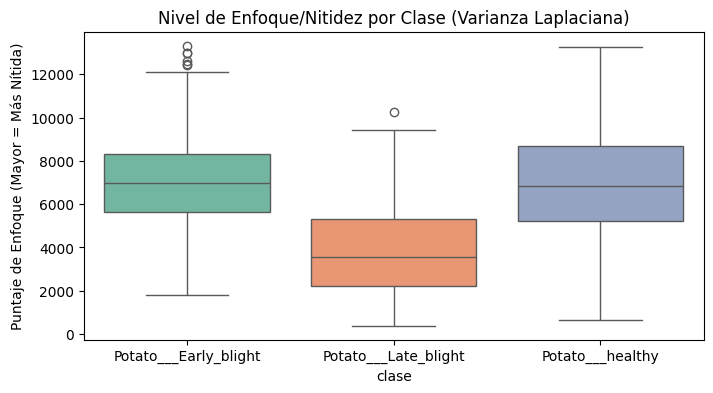

In [ ]:
import cv2

def calcular_enfoque(ruta_img):
    img = cv2.imread(ruta_img, cv2.IMREAD_GRAYSCALE)
    # Varianza del Laplaciano
    return cv2.Laplacian(img, cv2.CV_64F).var()

df_analisis['blur_score'] = df_analisis['ruta_completa'].apply(calcular_enfoque)

# Visualizar distribución de nitidez
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_analisis, x='clase', y='blur_score', palette='Set2')
plt.title("Nivel de Enfoque/Nitidez por Clase (Varianza Laplaciana)")
plt.ylabel("Puntaje de Enfoque (Mayor = Más Nítida)")
plt.show()

**Distribución de Brillo y Contraste Medio**

Diferentes condiciones de luz como el sol directo contra la sombra de laboratorio alteran drásticamente los valores de los píxeles

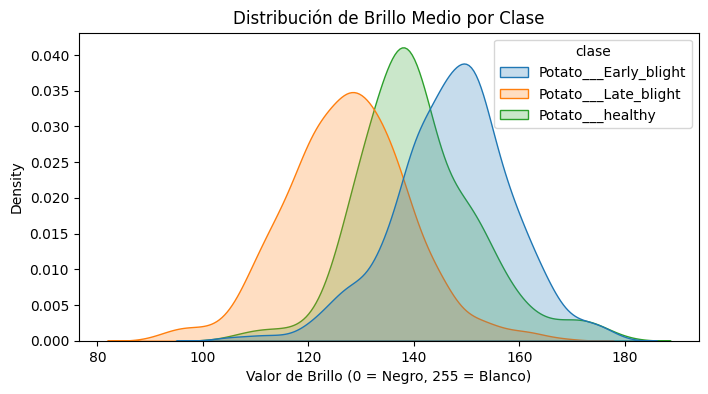

In [ ]:
def calcular_brillo_medio(ruta_img):
    img_bgr = cv2.imread(ruta_img)
    img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    # Canal V (Value = Brillo)
    return img_hsv[:, :, 2].mean()

df_analisis['brillo_medio'] = df_analisis['ruta_completa'].apply(calcular_brillo_medio)

plt.figure(figsize=(8, 4))
sns.kdeplot(data=df_analisis, x='brillo_medio', hue='clase', fill=True, common_norm=False)
plt.title("Distribución de Brillo Medio por Clase")
plt.xlabel("Valor de Brillo (0 = Negro, 255 = Blanco)")
plt.show()

**Calidad de los Datos**

In [ ]:
# Obtención de duplicados o parecidos(a un alto nivel)

def calcular_hashes(ruta_img):
    with open(ruta_img, "rb") as f:
        # Hash binario exacto (MD5)
        md5_hash = hashlib.md5(f.read()).hexdigest()

    # Hash perceptual visual (dHash: difference hash)
    with Image.open(ruta_img) as img:
        phash_val = str(imagehash.dhash(img))

    return md5_hash, phash_val

# Extraer hashes para todo el dataset
print("Auditando integridad y buscando imágenes duplicadas...")
hashes_md5 = []
hashes_perceptuales = []

for ruta in df_analisis["ruta_completa"]:
    m, p = calcular_hashes(ruta)
    hashes_md5.append(m)
    hashes_perceptuales.append(p)

df_analisis["md5"] = hashes_md5
df_analisis["dhash"] = hashes_perceptuales

# 1. Duplicados exactos (mismo archivo binario)
duplicados_exactos = df_analisis[df_analisis.duplicated(subset=["md5"], keep=False)]
total_dup_exactos = df_analisis.duplicated(subset=["md5"]).sum()

# 2. Duplicados perceptuales (mismo contenido visual)
duplicados_visuales = df_analisis[df_analisis.duplicated(subset=["dhash"], keep=False)]
total_dup_visuales = df_analisis.duplicated(subset=["dhash"]).sum()

print("--- REPORTE DE AUDITORÍA DE DUPLICADOS ---")
print(f"• Duplicados exactos (MD5): {total_dup_exactos}")
print(f"• Duplicados perceptuales (dHash): {total_dup_visuales}")

if total_dup_exactos > 0 or total_dup_visuales > 0:
    print("\nAlerta: Se detectaron imágenes repetidas. Conviene eliminar duplicados antes del split train/val/test.")
    display(duplicados_visuales.sort_values(by="dhash").head(6)[["clase", "nombre_archivo", "dhash"]])
else:
    print("\n✓ No se encontraron duplicados. Cada imagen del dataset es única.")

Auditando integridad y buscando imágenes duplicadas...
--- REPORTE DE AUDITORÍA DE DUPLICADOS ---
• Duplicados exactos (MD5): 0
• Duplicados perceptuales (dHash): 0

✓ No se encontraron duplicados. Cada imagen del dataset es única.


## **PREPARACIÓN DE LOS DATOS**

Nos centraremos antes de hacer cambios al dataset en hacer una división, donde aplicaremos cambios reales sobre la partición de testeo.

In [ ]:
!pip install -q split-folders

In [ ]:
import splitfolders

# 1. Definimos 70% entrenamiento, 15% validación, 15% prueba
# La semilla (seed) asegura que la división sea exactamente igual que en otras pruebas.
splitfolders.ratio(
    input=DATASET_DIR, # La ruta original
    output="/content/dataset_dividido",
    seed=42,
    ratio=(0.7, 0.15, 0.15),
    group_prefix=None
)

print("Partición estratificada completada. Nueva estructura en /content/dataset_dividido")

Copying files: 2152 files [00:00, 5522.12 files/s]

Partición estratificada completada. Nueva estructura en /content/dataset_dividido


Ahora como forma de tratar el desbalanceo de clases, modificamos los pesos guardando la relacion para que el modelo le de importancia a la clase que menos variedad tienen(healthy).

In [ ]:
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
from tensorflow import keras

In [ ]:
from tensorflow.keras import layers

In [ ]:
from tensorflow.keras import Sequential

In [ ]:
# Cargar dataset de entrenamiento (solo para extraer las etiquetas y calcular pesos)
train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/dataset_dividido/train",
    labels='inferred',
    label_mode='int'
)

# Extraer etiquetas reales de los lotes
y_train = np.concatenate([y for x, y in train_ds], axis=0)
clases_unicas = np.unique(y_train)

# Calcular pesos penalizadores
pesos = compute_class_weight(
    class_weight='balanced',
    classes=clases_unicas,
    y=y_train
)

pesos_clase_dict = dict(zip(clases_unicas, pesos))
print(f"Pesos aplicados a la función de pérdida: {pesos_clase_dict}")
# Notarás que el peso de la clase 'Sana' será significativamente mayor.

Found 1506 files belonging to 3 classes.
Pesos aplicados a la función de pérdida: {np.int32(0): np.float64(0.7171428571428572), np.int32(1): np.float64(0.7171428571428572), np.int32(2): np.float64(4.735849056603773)}


Finalmente vamos a agregar una fase de personalización a las capas que después va a implementar el modelo. Esto hace que no generemos un dataset más pesado y con muchas imagenes dado al *Data Augmentation*.

Tenemos que definir entonces **Dos clases**:

1. RandomGaussianBlur: Desenfoque gaussiano real, aplicado con cierta probabilidad durante el entrenamiento. Se aplica a todas las clases (no solo a las nítidas) para que la nitidez deje de ser una señal confiable de clase, en vez de simplemente igualar promedios


2. RandomGaussianNoise: Ruido gaussiano aplicado con cierta probabilidad (no en el 100% de los pasos), para evitar sobre-acumular perturbaciones junto con el blur y el resto del augmentation.

In [ ]:
class RandomGaussianBlur(layers.Layer):
    def __init__(self, probability=0.3, kernel_size=5, sigma_range=(1.0, 2.5), **kwargs):
        super().__init__(**kwargs)
        self.probability = probability
        self.kernel_size = kernel_size
        self.sigma_range = sigma_range

    def _gaussian_kernel(self, sigma):
        ax = tf.range(-(self.kernel_size // 2), self.kernel_size // 2 + 1, dtype=tf.float32)
        xx, yy = tf.meshgrid(ax, ax)
        kernel = tf.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
        return kernel / tf.reduce_sum(kernel)

    def _blur_una_imagen(self, img):
        sigma = tf.random.uniform([], self.sigma_range[0], self.sigma_range[1])
        kernel = self._gaussian_kernel(sigma)
        kernel = tf.reshape(kernel, [self.kernel_size, self.kernel_size, 1, 1])
        kernel = tf.tile(kernel, [1, 1, 3, 1])  # mismo kernel para R, G y B
        img_batched = tf.expand_dims(img, axis=0)
        blurred = tf.nn.depthwise_conv2d(img_batched, kernel, strides=[1, 1, 1, 1], padding="SAME")
        return tf.squeeze(blurred, axis=0)

    def call(self, images, training=None):
        if not training:
            return images
        blurred = tf.map_fn(self._blur_una_imagen, images)
        aplicar = tf.random.uniform([tf.shape(images)[0]]) < self.probability
        aplicar = tf.reshape(aplicar, [-1, 1, 1, 1])
        return tf.where(aplicar, blurred, images)

In [ ]:
class RandomGaussianNoise(layers.Layer):
    def __init__(self, stddev=0.05, probability=0.3, **kwargs):
        super().__init__(**kwargs)
        self.stddev = stddev
        self.probability = probability
        self.noise_layer = layers.GaussianNoise(stddev)

    def call(self, images, training=None):
        if not training:
            return images
        ruidosas = self.noise_layer(images, training=True)
        aplicar = tf.random.uniform([tf.shape(images)[0]]) < self.probability
        aplicar = tf.reshape(aplicar, [-1, 1, 1, 1])
        return tf.where(aplicar, ruidosas, images)

In [ ]:
capas_preprocesamiento = Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.10, interpolation="nearest"),
    layers.RandomZoom(0.10, interpolation="nearest"),
    layers.RandomContrast(0.1),
    layers.RandomBrightness(0.1, value_range=(0, 255)),
    layers.Rescaling(1. / 255),
], name="Preparacion_y_Augmentation")

Como paso final de esta sección, organizamos las imagenes en tensores de datos, formas organizadas para que el modelo pueda "ver" imagenes y aprenda de ellas.

Usamos la misma seed que anteriormente para poder tener un control en futuras pruebas.

In [ ]:
import tensorflow as tf

# Parámetros de carga
BATCH_SIZE = 32
# Cargamos en resolución original (256x256), la capa Resizing de tu bloque de Augmentation lo bajará a 224x224
IMG_SIZE = (256, 256)
directorio_base = "/content/dataset_dividido"

# 1. Crear tensor de Entrenamiento (Train)
print("--- Cargando datos de Entrenamiento ---")
train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{directorio_base}/train",
    shuffle=True,
    seed = 42,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

# 2. Crear tensor de Validación (Val)
print("\n--- Cargando datos de Validación ---")
val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{directorio_base}/val",
    shuffle=True,
    seed  = 42,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

# 3. Crear tensor de Prueba (Test)
print("\n--- Cargando datos de Prueba ---")
test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{directorio_base}/test",
    shuffle=False, # No es necesario mezclar las fotos de prueba
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE
)

# Guardar los nombres de las clases para las gráficas posteriores
class_names = train_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=42).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

print("\n¡Tensores de datos optimizados y listos para entrenar!")
print(class_names)

--- Cargando datos de Entrenamiento ---
Found 1506 files belonging to 3 classes.

--- Cargando datos de Validación ---
Found 322 files belonging to 3 classes.

--- Cargando datos de Prueba ---
Found 324 files belonging to 3 classes.

¡Tensores de datos optimizados y listos para entrenar!
['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


## **MODELADO**

Para este momento ya todo está listo para configurar la red neuronal que queremos crear. La idea es configurar uno mismo su propia red neuronal.

Esperamos que en proximas entregas se pueda permitir el uso de modelos preentrenados utilizando *transfer learning*

In [ ]:
from tensorflow.keras import callbacks, models

In [ ]:
from tensorflow.keras.optimizers import Adam

In [ ]:
#modificar pesos_clase_dict
pesos_clase_dict[2] = np.float64(2.25)

In [ ]:
pesos_clase_dict

{np.int32(0): np.float64(0.7171428571428572),
 np.int32(1): np.float64(0.7171428571428572),
 np.int32(2): np.float64(2.25)}

In [ ]:
  def bloque_doble(filtros, k_primera=3):
      return [
          layers.Conv2D(filtros, k_primera, padding="same", use_bias=False),
          layers.GroupNormalization(groups=8),
          layers.Activation("relu"),
          layers.Conv2D(filtros, 3, padding="same", use_bias=False),
          layers.GroupNormalization(groups=8),
          layers.Activation("relu"),
          layers.MaxPooling2D(2),
      ]

  modelo_papa_v6 = models.Sequential(
      [layers.Input(shape=(256, 256, 3)), capas_preprocesamiento]
      + bloque_doble(32, k_primera=5)
      + bloque_doble(64)
      + bloque_doble(128)
      + bloque_doble(256)
      + bloque_doble(256)
      + [
          layers.GlobalAveragePooling2D(),
          layers.Dense(128, activation="relu"),
          layers.Dropout(0.4),                 # dropout DESPUES de la activacion, sin BN detras
          layers.Dense(3, activation="softmax"),
      ],
      name="modelo_papa_v6",
  )

  modelo_papa_v6.compile(
      optimizer=Adam(learning_rate=5e-4),
      loss="sparse_categorical_crossentropy",
      metrics=["accuracy"],
  )

  cbs = [
      callbacks.EarlyStopping(monitor="val_loss", patience=12,
                              restore_best_weights=True, verbose=1),
      callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4,
                                  min_lr=1e-6, verbose=1),
  ]

  historial = modelo_papa_v6.fit(
      train_ds,
      validation_data=val_ds,
      epochs=80,
      class_weight=pesos_clase_dict,   # {0: 0.717, 1: 0.717, 2: 2.25}
      callbacks=cbs,
  )

Epoch 1/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 33s 535ms/step - accuracy: 0.4243 - loss: 0.9477 - val_accuracy: 0.4658 - val_loss: 0.9959 - learning_rate: 5.0000e-04
Epoch 2/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 24s 497ms/step - accuracy: 0.4661 - loss: 0.8757 - val_accuracy: 0.6429 - val_loss: 0.8862 - learning_rate: 5.0000e-04
Epoch 3/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 484ms/step - accuracy: 0.7278 - loss: 0.6068 - val_accuracy: 0.8634 - val_loss: 0.3887 - learning_rate: 5.0000e-04
Epoch 4/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 489ms/step - accuracy: 0.7390 - loss: 0.5894 - val_accuracy: 0.8665 - val_loss: 0.3901 - learning_rate: 5.0000e-04
Epoch 5/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 24s 494ms/step - accuracy: 0.7463 - loss: 0.4719 - val_accuracy: 0.8665 - val_loss: 0.4315 - learning_rate: 5.0000e-04
Epoch 6/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 24s 494ms/step - accuracy: 0.8347 - loss: 0.3635 - val_accuracy: 0.8820 - val_loss: 0.2941 - learning_rate: 5.0000e-04
Epoch 7/80
48/48 ━━━━━━━━━━━━━━━━━━━━ 23s 490ms/step - acc

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

def predecir(modelo, ds):
    y_true = np.concatenate([y.numpy() for _, y in ds])
    y_pred = np.argmax(modelo.predict(ds, verbose=0), axis=1)
    return y_true, y_pred

print("train (inferencia):", modelo_papa_v6.evaluate(train_ds, verbose=0))  # debe parecerse a val

print("=== VALIDACION ===")
yv, pv = predecir(modelo_papa_v6, val_ds)
print(confusion_matrix(yv, pv))
print(classification_report(yv, pv, target_names=class_names, digits=4))

# TEST: ejecutar UNA vez
print("=== TEST ===")
loss_test, acc_test = modelo_papa_v6.evaluate(test_ds, verbose=0)
print(f"Accuracy: {acc_test:.4f}  (meta debe ser > 0.985)")
print(f"Error 1-acc: {1 - acc_test:.4f}  (meta <= 0.03)")
yt, pt = predecir(modelo_papa_v6, test_ds)
print(confusion_matrix(yt, pt))
print(classification_report(yt, pt, target_names=class_names, digits=4))

train (inferencia): [0.01708320714533329, 0.9953519105911255]
=== VALIDACION ===
[[148   2   0]
 [  1 147   2]
 [  0   2  20]]
                       precision    recall  f1-score   support

Potato___Early_blight     0.9933    0.9867    0.9900       150
 Potato___Late_blight     0.9735    0.9800    0.9767       150
     Potato___healthy     0.9091    0.9091    0.9091        22

             accuracy                         0.9783       322
            macro avg     0.9586    0.9586    0.9586       322
         weighted avg     0.9783    0.9783    0.9783       322

=== TEST ===
Accuracy: 0.9784  (meta debe ser > 0.985)
Error 1-acc: 0.0216  (meta <= 0.03)
Loss: 0.0506  (meta <= 0.03 si 'error' = loss)
[[149   1   0]
 [  1 146   3]
 [  0   2  22]]
                       precision    recall  f1-score   support

Potato___Early_blight     0.9933    0.9933    0.9933       150
 Potato___Late_blight     0.9799    0.9733    0.9766       150
     Potato___healthy     0.8800    0.9167    0.8980   

In [ ]:
modelo_papa_v6.save("/content/modelo_v6_s1.keras")

## **EVALUACIÓN DEL MODELO**

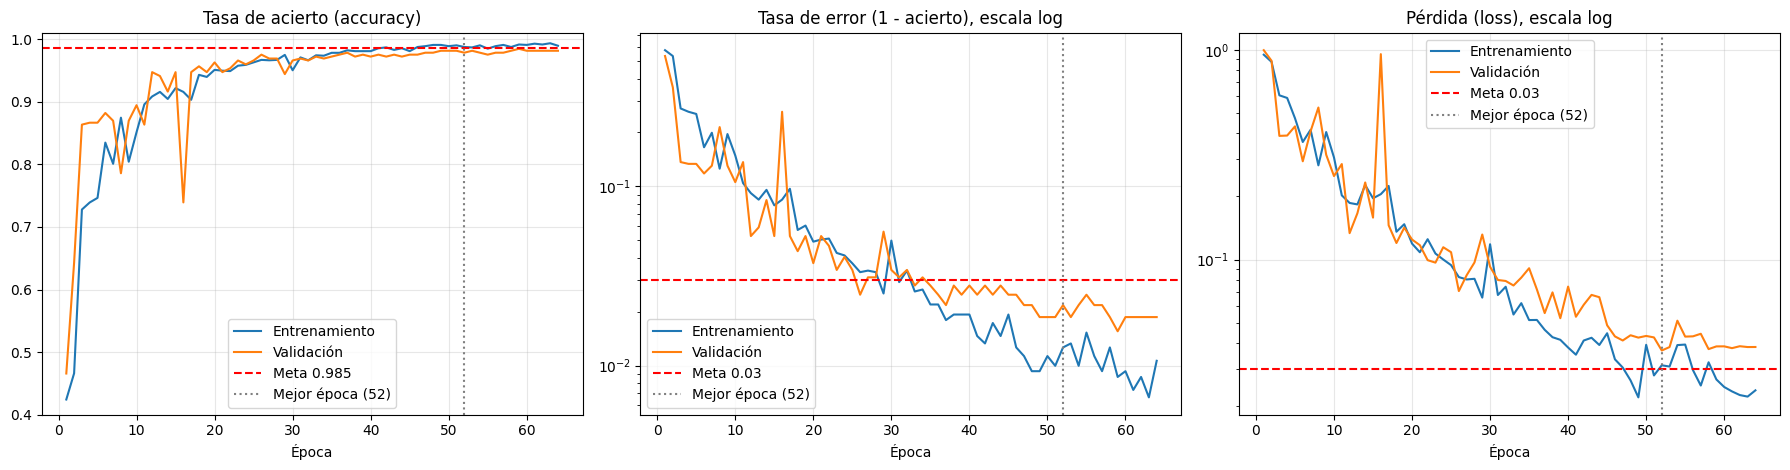

In [ ]:
h = historial.history
epocas = np.arange(1, len(h["accuracy"]) + 1)
mejor = int(np.argmin(h["val_loss"])) + 1          # epoca cuyos pesos restauro EarlyStopping
err_train = 1 - np.array(h["accuracy"])
err_val = 1 - np.array(h["val_accuracy"])

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))

ax[0].plot(epocas, h["accuracy"], label="Entrenamiento")
ax[0].plot(epocas, h["val_accuracy"], label="Validación")
ax[0].axhline(0.985, color="red", ls="--", label="Meta 0.985")
ax[0].set_title("Tasa de acierto (accuracy)")
ax[0].set_ylim(0.4, 1.01)

ax[1].plot(epocas, err_train, label="Entrenamiento")
ax[1].plot(epocas, err_val, label="Validación")
ax[1].axhline(0.03, color="red", ls="--", label="Meta 0.03")
ax[1].set_yscale("log")
ax[1].set_title("Tasa de error (1 - acierto), escala log")

ax[2].plot(epocas, h["loss"], label="Entrenamiento")
ax[2].plot(epocas, h["val_loss"], label="Validación")
ax[2].axhline(0.03, color="red", ls="--", label="Meta 0.03")
ax[2].set_yscale("log")
ax[2].set_title("Pérdida (loss), escala log")

for a in ax:
    a.axvline(mejor, color="gray", ls=":", label=f"Mejor época ({mejor})")
    a.set_xlabel("Época")
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()
plt.show()

=== TABLA DE MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ===


,precision,recall,f1-score,support
Potato___Early_blight,0.9933,0.9933,0.9933,150.0000
Potato___Late_blight,0.9799,0.9733,0.9766,150.0000
Potato___healthy,0.8800,0.9167,0.8980,24.0000
accuracy,0.9784,0.9784,0.9784,0.9784
macro avg,0.9511,0.9611,0.9560,324.0000
weighted avg,0.9787,0.9784,0.9785,324.0000


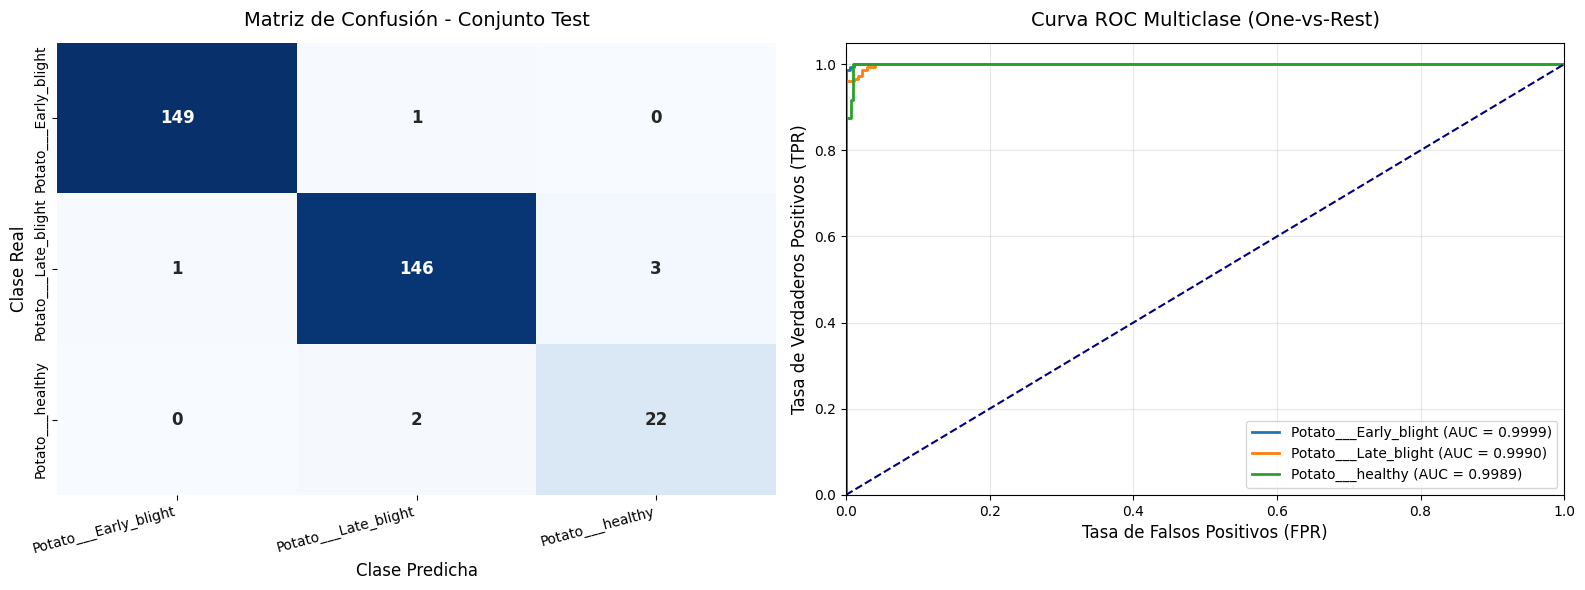

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

# 1. Obtener etiquetas reales y predicciones del conjunto de prueba
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
y_probs = modelo_papa_v6.predict(test_ds, verbose=0)
y_pred = np.argmax(y_probs, axis=1)

# 2. Generar y mostrar Tabla de Métricas de Evaluación
report_dict = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)
df_metrics = pd.DataFrame(report_dict).transpose()
print("=== TABLA DE MÉTRICAS DE EVALUACIÓN (CONJUNTO DE PRUEBA) ===")
display(df_metrics.round(4))

# Crear figura principal para Matriz de Confusión y Curva ROC
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 3. Graficar Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=ax[0],
    cbar=False,
    annot_kws={"size": 12, "weight": "bold"}
)
ax[0].set_title("Matriz de Confusión - Conjunto Test", fontsize=14, pad=12)
ax[0].set_ylabel("Clase Real", fontsize=12)
ax[0].set_xlabel("Clase Predicha", fontsize=12)
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=15, ha="right")

# 4. Graficar Curva ROC para cada clase
n_classes = len(class_names)
y_true_bin = label_binarize(y_true, classes=range(n_classes))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_probs[:, i])
    roc_auc = auc(fpr, tpr)
    ax[1].plot(
        fpr,
        tpr,
        lw=2,
        label=f"{class_names[i]} (AUC = {roc_auc:.4f})"
    )

ax[1].plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--")
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel("Tasa de Falsos Positivos (FPR)", fontsize=12)
ax[1].set_ylabel("Tasa de Verdaderos Positivos (TPR)", fontsize=12)
ax[1].set_title("Curva ROC Multiclase (One-vs-Rest)", fontsize=14, pad=12)
ax[1].legend(loc="lower right", fontsize=10)
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**PREDICCION DE IMAGENES**

Usamos el modelo que exportamos mediante la funcionalidad *.predict*

In [ ]:
import random
from pathlib import Path

def predecir_imagen_aleatoria(subcarpeta, modelo):
    dir_test = Path("/content/dataset_dividido/test") / subcarpeta

    if not dir_test.exists():
        raise FileNotFoundError(f"La carpeta {dir_test} no existe. Elige entre {class_names}")

    imagenes = list(dir_test.glob("*.*"))
    if not imagenes:
        raise FileNotFoundError(f"No se encontraron imágenes en {dir_test}")

    ruta_aleatoria = random.choice(imagenes)
    print(f"Imagen seleccionada aleatoriamente: {ruta_aleatoria.name}")

    # Cargar y preprocesar la imagen para el modelo
    img = tf.keras.utils.load_img(str(ruta_aleatoria), target_size=(256, 256))
    x = tf.keras.utils.img_to_array(img)[None] # valores 0-255

    # Predicción
    p = modelo.predict(x, verbose=0)[0]
    clase_predicha = class_names[int(p.argmax())]
    confianza = float(p.max())

    # Mostrar la imagen con matplotlib
    plt.figure(figsize=(6, 6))
    plt.imshow(img)
    plt.title(f"Predicción: {clase_predicha}\nConfianza: {confianza:.2%}", fontsize=14, color="green" if clase_predicha == subcarpeta else "red")
    plt.axis("off")
    plt.show()

    return clase_predicha, confianza, p

Imagen seleccionada aleatoriamente: 58a98860-86d8-41e7-9f8c-cc2ca5e90012___RS_HL 1758.JPG


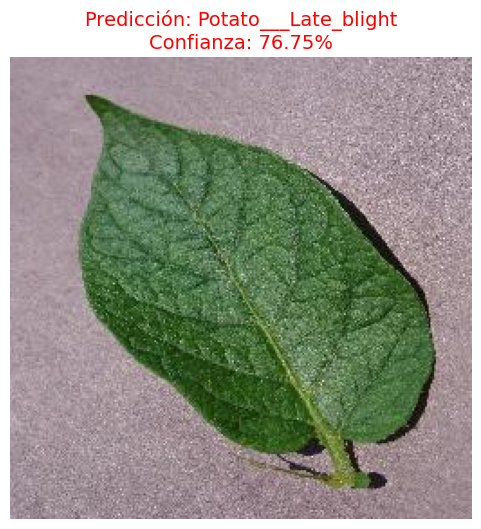

('Potato___Late_blight', 0.7674540877342224, array([7.1101158e-06, 7.6745409e-01, 2.3253876e-01], dtype=float32))


In [ ]:
print(predecir_imagen_aleatoria("Potato___healthy", modelo_papa_v6))

In [ ]:
import shutil
from google.colab import files

# 1. Definir la ruta de la carpeta de test y el nombre del archivo de salida
ruta_test = "/content/dataset_dividido/test"
archivo_zip = "/content/dataset_test_dividido"

print("Comprimiendo la carpeta de test...")
# 2. Crear un archivo ZIP con el contenido de la carpeta test
shutil.make_archive(archivo_zip, 'zip', ruta_test)

print("¡Compresión completada! Iniciando descarga...")
# 3. Descargar el archivo ZIP generado
files.download(f"{archivo_zip}.zip")

Comprimiendo la carpeta de test...
¡Compresión completada! Iniciando descarga...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>